***Шалабанов Александр - Notebook для создания модели прогнозирования***

Загружаем библиотеки

In [366]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mamoUtils as mu
np.__version__, pd.__version__

('2.5.5', '3.1.1')

Загрузка данных из папки data

In [367]:
data = pd.read_csv("data/train.csv")
print(data.shape)
data.head()

(1656, 37)


,sku,unit,2019-01,2019-02,2019-03,2019-04,2019-05,2019-06,2019-07,2019-08,...,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-08,2021-09,2021-10,2021-11
0,0,ШТ,128.0,125.0,179.0,199.0,204.0,246.0,172.0,235.0,...,379.0,250.0,317.0,172.0,193.0,173.0,121.0,318.0,328.0,208.0
1,1,ШТ,65.0,64.0,54.0,91.0,74.0,91.0,138.0,115.0,...,68.0,65.0,72.0,82.0,85.0,69.0,75.0,100.0,72.0,89.0
2,2,ШТ,157.0,205.0,210.0,205.0,265.0,248.0,292.0,268.0,...,334.0,380.0,409.0,309.0,388.0,438.0,404.0,293.0,274.0,381.0
3,3,ШТ,2450.0,2280.0,2144.0,2283.0,2177.0,2888.0,3066.0,2288.0,...,2806.0,2085.0,1984.0,2086.0,2871.0,2204.0,1821.0,2187.0,1672.0,1665.0
4,4,ШТ,119.0,154.0,154.0,270.0,513.0,718.0,720.0,292.0,...,222.0,258.0,289.0,662.0,759.0,616.0,365.0,321.0,392.0,409.0


In [368]:
testData = pd.read_csv("data/test.csv")
print(testData.shape)
testData.head()

(4968, 4)


,id,sku,unit,month
0,0_2021-12,0,ШТ,2021-12
1,0_2022-01,0,ШТ,2022-01
2,0_2022-02,0,ШТ,2022-02
3,1_2021-12,1,ШТ,2021-12
4,1_2022-01,1,ШТ,2022-01


Разобьём наш Data в удобный вид разделив их по времени

In [369]:

splitter = mu.SplitDateOnColumn()
splittedData = splitter.transform(data)
splittedData.head()

,sku,unit,month,resultValue
0,0,ШТ,2019-01,128.0
1,0,ШТ,2019-02,125.0
2,0,ШТ,2019-03,179.0
3,0,ШТ,2019-04,199.0
4,0,ШТ,2019-05,204.0


Далее для ещё более удобно записи и прогнозирования разделим месяцы на год и месяц. Написать его следует так, чтобы и тестовые данные можно было обработать

In [370]:

dateSplitter = mu.SplitDateOnYearsMonth()
transformedTrainData = dateSplitter.transform(splittedData)
transformedTrainData

,sku,unit,resultValue,years,month
0,0,ШТ,128.0,2019,1
1,0,ШТ,125.0,2019,2
2,0,ШТ,179.0,2019,3
3,0,ШТ,199.0,2019,4
4,0,ШТ,204.0,2019,5
...,...,...,...,...,...
57955,1655,ШТ,121.0,2021,7
57956,1655,ШТ,146.0,2021,8
57957,1655,ШТ,123.0,2021,9
57958,1655,ШТ,124.0,2021,10


Данные мы преобразовали теперь можно начать с ними работать, начнём с разведочного анализа и получения корреляции признаков, так же будем пробовать построить новые признаки с основой на нынешние

In [371]:
transformedTrainData.drop("unit", axis=1).corr().round(2)

,sku,resultValue,years,month
sku,1.0,0.00,0.00,0.00
resultValue,0.0,1.00,0.02,0.03
years,0.0,0.02,1.00,-0.06
month,0.0,0.03,-0.06,1.00


Как мы видим - корреляция от года и месяца слабая, а от sku вообще отсутствует. Сейчас посмотрим что находится в категориальном признаке

In [372]:
print(transformedTrainData.loc[..., "unit"].describe())
print(transformedTrainData.loc[..., "unit"].unique())
transformedTrainData.loc[..., "unit"].value_counts()

count     57960
unique       14
top          ШТ
freq      43120
Name: unit, dtype: object
<StringArray>
[ 'ШТ', 'Меш',  'УП', 'Лст', 'ПАР',  'Пм', 'РУЛ', 'Вдр',  'КГ',   'М', 'Кмп',
  'ПК', 'Бнк', 'Мкр']
Length: 14, dtype: str


unit
ШТ     43120
УП      4865
Меш     2415
КГ      1820
Лст     1645
Пм       945
РУЛ      805
М        735
ПАР      595
Вдр      595
ПК       175
Кмп      140
Мкр       70
Бнк       35
Name: count, dtype: int64

Видим, что ШТ больше всего в выборке как и УП. По сути не понятно, можно ли некоторые признаки по типу УП, ШТ, РУЛ и ТП. заменить на обозначение ШТ так как они означают одну и ту же штучную категорию. *В будущем проверим* Сейчас посмотрим график самых частых sku

In [373]:
transformedTrainData.loc[..., ["sku", "resultValue"]].sort_values("resultValue")

,sku,resultValue
43605,1245,-6564.0
39842,1138,-1485.0
36355,1038,-400.0
36836,1052,-286.0
49383,1410,-265.0
...,...,...
20165,576,386867.0
20177,576,423183.0
19899,568,458707.0
20178,576,531664.0


Видим интересную картину, часть товаров имеет отрицательные продажи, это значит что товары возвращали. Создадим график для них тоже

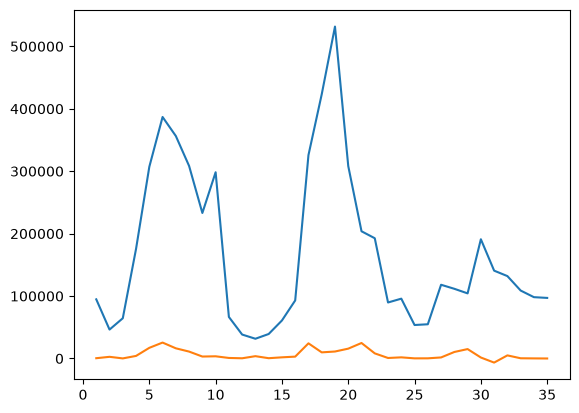

In [374]:
dataForGraphicMax = transformedTrainData[transformedTrainData["sku"] == 576]
plt.plot((dataForGraphicMax["years"] - 2019) * 12 + dataForGraphicMax["month"], dataForGraphicMax["resultValue"])
dataForGraphicMin = transformedTrainData[transformedTrainData["sku"] == 1245]
plt.plot((dataForGraphicMin["years"] - 2019) * 12 + dataForGraphicMin["month"], dataForGraphicMin["resultValue"])

По графику есть идея для работы с месяцем, а именно работать с ним как с синусом

Видно что товар с отрицательными значениями не имеет большого спроса, при этом имеет возвраты. Думаю возвраты можно будет залить нулями так как они не особо нам нужны, если судить про продажи. Так же видно смешные пики, похожие на выбросы, почему смешные? потому что в теории при масштабировании это решается с помощью RobustScaler
Так же думаю месяц можно будет представить в виде OHE, так как мы видим месяцов в разные года, так что вполне считаю в будущем можно будет года масштабировать с помощью MinMaxScaler, а месяцы с помощью OHE

In [375]:
transformedTrainData.loc[transformedTrainData['resultValue'] < 0, 'resultValue'] = 0
transformedTrainData

,sku,unit,resultValue,years,month
0,0,ШТ,128.0,2019,1
1,0,ШТ,125.0,2019,2
2,0,ШТ,179.0,2019,3
3,0,ШТ,199.0,2019,4
4,0,ШТ,204.0,2019,5
...,...,...,...,...,...
57955,1655,ШТ,121.0,2021,7
57956,1655,ШТ,146.0,2021,8
57957,1655,ШТ,123.0,2021,9
57958,1655,ШТ,124.0,2021,10


In [376]:
transformedTrainData.loc[..., ["sku", "resultValue"]].sort_values("resultValue")

,sku,resultValue
39633,1132,0.0
39632,1132,0.0
39631,1132,0.0
39630,1132,0.0
39629,1132,0.0
...,...,...
20165,576,386867.0
20177,576,423183.0
19899,568,458707.0
20178,576,531664.0


<Axes: xlabel='unit'>

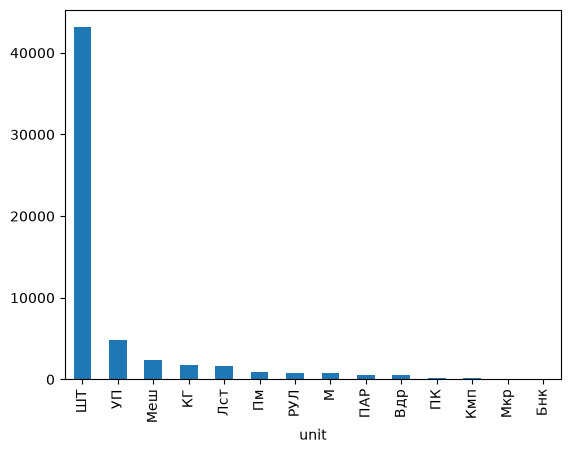

In [377]:

transformedTrainData['unit'].value_counts().plot(x='unit', kind='bar')

Видим что ШТ болье всего и так по убыванию, в теории эта несбалансированность категорий может повлиять на результат

In [378]:
transformedTrainData.isna().sum()

sku            0
unit           0
resultValue    0
years          0
month          0
dtype: int64

Чтоже думаю можно создать признаки c основой на прошлые года, собственно создадим признаки прошлого и позапрошлого года, так называемые lag. Однозначно образуются NaN, так что их мы будем заливать медианной за все года, чтобы сохранить сезонность признаков

In [379]:
def add_lags(dataFrame, lags):
    df = dataFrame.copy()
    resLags = []
    for i in lags:
        resLags += [f'lag_{i}']
        fill_lag(df, i )
    return (df, resLags)

def fill_lag(dataFrame, shift):
    lagStr = f'lag_{shift}'
    dataFrame[lagStr] = dataFrame.groupby('sku')['resultValue'].shift(shift)
    
    dataFrame[lagStr] = dataFrame[lagStr].fillna(dataFrame.groupby(['sku', 'month'])[lagStr].transform('median'))
    if(dataFrame[lagStr].isna().sum() > 0):
        months = dataFrame[['month']]
        months['month'] = months['month'] + shift
        
        while (len(months.loc[months['month'] > 12, 'month']) > 0):
            months.loc[months['month']  > 12, 'month'] = months.loc[months['month'] > 12, 'month'] - 12
        
        monthResDataFrame = dataFrame[['sku', 'resultValue']].join(months)
        medianRes = monthResDataFrame.groupby(['sku', 'month']).agg(medianRes = ('resultValue', 'median'))
        for i in range(0, len(dataFrame)):
            data = dataFrame.iloc[i]
            if(np.isnan(data[lagStr])):
                data[lagStr] = medianRes['medianRes'][data['sku']][data['month']]
                dataFrame.iloc[i] = data
dataWithLags, lags = add_lags(transformedTrainData, [3, 12, 13, 24])

In [380]:
dataWithLags

,sku,unit,resultValue,years,month,lag_3,lag_12,lag_13,lag_24
0,0,ШТ,128.0,2019,1,182.5,133.0,160.0,128.0
1,0,ШТ,125.0,2019,2,162.0,148.0,133.0,125.0
2,0,ШТ,179.0,2019,3,215.5,148.5,148.0,179.0
3,0,ШТ,199.0,2019,4,128.0,212.5,148.5,199.0
4,0,ШТ,204.0,2019,5,125.0,174.0,212.5,204.0
...,...,...,...,...,...,...,...,...,...
57955,1655,ШТ,121.0,2021,7,128.0,161.0,183.0,131.0
57956,1655,ШТ,146.0,2021,8,112.0,202.0,161.0,155.0
57957,1655,ШТ,123.0,2021,9,115.0,160.0,202.0,124.0
57958,1655,ШТ,124.0,2021,10,121.0,174.0,160.0,97.0


Далее будем добавлять скользящее среднее за 3, 6 и 12 месяцев

In [381]:
def add_rolling_mean(dataFrame, lag_column, windows):
    df = dataFrame.copy()
    res_rm_strs = []
    for i in windows:
        rm_str = f'rolling_mean_{i}'
        res_rm_strs += [rm_str]
        df[rm_str] = df.groupby('sku')[lag_column].transform(lambda x: x.rolling(i).mean())
        df[rm_str] = df[rm_str].fillna(df.groupby(['sku', 'month'])[rm_str].transform('median'))
    return (df, res_rm_strs)
rollingData, rolling_means = add_rolling_mean(dataWithLags, 'lag_3', [3, 6, 12])
print(rolling_means)
rollingData.head(12)

['rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12']


,sku,unit,resultValue,years,month,lag_3,lag_12,lag_13,lag_24,rolling_mean_3,rolling_mean_6,rolling_mean_12
0,0,ШТ,128.0,2019,1,182.5,133.0,160.0,128.0,198.666667,188.333333,176.270833
1,0,ШТ,125.0,2019,2,162.0,148.0,133.0,125.0,191.333333,186.333333,176.812500
2,0,ШТ,179.0,2019,3,215.5,148.5,148.0,179.0,186.666667,191.666667,179.125000
3,0,ШТ,199.0,2019,4,128.0,212.5,148.5,199.0,168.500000,201.666667,187.750000
4,0,ШТ,204.0,2019,5,125.0,174.0,212.5,204.0,156.166667,216.833333,198.333333
5,0,ШТ,246.0,2019,6,179.0,183.5,174.0,246.0,144.000000,165.333333,201.291667
6,0,ШТ,172.0,2019,7,199.0,176.5,183.5,172.0,167.666667,168.083333,206.208333
7,0,ШТ,235.0,2019,8,204.0,184.0,176.5,235.0,194.000000,175.083333,204.875000
8,0,ШТ,238.0,2019,9,246.0,229.5,184.0,238.0,216.333333,180.166667,202.666667
9,0,ШТ,228.0,2019,10,172.0,182.5,229.5,228.0,207.333333,187.500000,202.708333


In [382]:
def add_rolling_std(dataFrame, lag_column, windows):
    df = dataFrame.copy()
    res_rm_strs = []
    for i in windows:
        rm_str = f'rolling_std_{i}'
        res_rm_strs += [rm_str]
        df[rm_str] = df.groupby('sku')[lag_column].transform(lambda x: x.rolling(i).std())
        df[rm_str] = df[rm_str].fillna(df.groupby(['sku', 'month'])[rm_str].transform('median'))
    return (df, res_rm_strs)
rollingData, rolling_std = add_rolling_std(rollingData, 'lag_3', [3, 6, 12])
print(rolling_means)
rollingData.head(12)

['rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12']


,sku,unit,resultValue,years,month,lag_3,lag_12,lag_13,lag_24,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12
0,0,ШТ,128.0,2019,1,182.5,133.0,160.0,128.0,198.666667,188.333333,176.270833,27.411994,32.723092,38.574363
1,0,ШТ,125.0,2019,2,162.0,148.0,133.0,125.0,191.333333,186.333333,176.812500,45.408966,39.142589,39.200569
2,0,ШТ,179.0,2019,3,215.5,148.5,148.0,179.0,186.666667,191.666667,179.125000,26.992283,46.747301,45.457834
3,0,ШТ,199.0,2019,4,128.0,212.5,148.5,199.0,168.500000,201.666667,187.750000,44.110656,63.456205,54.036608
4,0,ШТ,204.0,2019,5,125.0,174.0,212.5,204.0,156.166667,216.833333,198.333333,51.406063,67.691485,61.680763
5,0,ШТ,246.0,2019,6,179.0,183.5,174.0,246.0,144.000000,165.333333,201.291667,30.347982,34.727031,62.834347
6,0,ШТ,172.0,2019,7,199.0,176.5,183.5,172.0,167.666667,168.083333,206.208333,38.279673,36.941057,66.071832
7,0,ШТ,235.0,2019,8,204.0,184.0,176.5,235.0,194.000000,175.083333,204.875000,13.228757,39.451764,65.959133
8,0,ШТ,238.0,2019,9,246.0,229.5,184.0,238.0,216.333333,180.166667,202.666667,25.813433,46.952813,62.781952
9,0,ШТ,228.0,2019,10,172.0,182.5,229.5,228.0,207.333333,187.500000,202.708333,37.112442,40.113589,63.031036


In [383]:
def add_season_ratio(dataFrame, lag_column):
    df = dataFrame.copy()
    mean = dataFrame.groupby(['sku', 'month'])['resultValue'].transform('mean')
    df['season_ratio'] = df[lag_column] / (mean + 1)
    return (df, ['season_ratio'])
seasonedData, season_col = add_season_ratio(rollingData, 'lag_3')
print(season_col)
seasonedData.head(12)

['season_ratio']


,sku,unit,resultValue,years,month,lag_3,lag_12,lag_13,lag_24,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_ratio
0,0,ШТ,128.0,2019,1,182.5,133.0,160.0,128.0,198.666667,188.333333,176.270833,27.411994,32.723092,38.574363,0.906457
1,0,ШТ,125.0,2019,2,162.0,148.0,133.0,125.0,191.333333,186.333333,176.812500,45.408966,39.142589,39.200569,0.716814
2,0,ШТ,179.0,2019,3,215.5,148.5,148.0,179.0,186.666667,191.666667,179.125000,26.992283,46.747301,45.457834,1.175455
3,0,ШТ,199.0,2019,4,128.0,212.5,148.5,199.0,168.500000,201.666667,187.750000,44.110656,63.456205,54.036608,0.515436
4,0,ШТ,204.0,2019,5,125.0,174.0,212.5,204.0,156.166667,216.833333,198.333333,51.406063,67.691485,61.680763,0.717017
5,0,ШТ,246.0,2019,6,179.0,183.5,174.0,246.0,144.000000,165.333333,201.291667,30.347982,34.727031,62.834347,0.953819
6,0,ШТ,172.0,2019,7,199.0,176.5,183.5,172.0,167.666667,168.083333,206.208333,38.279673,36.941057,66.071832,1.128544
7,0,ШТ,235.0,2019,8,204.0,184.0,176.5,235.0,194.000000,175.083333,204.875000,13.228757,39.451764,65.959133,1.243902
8,0,ШТ,238.0,2019,9,246.0,229.5,184.0,238.0,216.333333,180.166667,202.666667,25.813433,46.952813,62.781952,0.946154
9,0,ШТ,228.0,2019,10,172.0,182.5,229.5,228.0,207.333333,187.500000,202.708333,37.112442,40.113589,63.031036,0.741379


In [384]:
def add_season_deviation(dataFrame, lag_column):
    df = dataFrame.copy()
    mean = dataFrame.groupby(['sku', 'month'])['resultValue'].transform('mean')
    df['season_deviation'] = df[lag_column] - mean
    return (df, ['season_deviation'])
seasonedData, season_dev_col = add_season_deviation(seasonedData, 'lag_3')
print(season_dev_col)
seasonedData.head(12)

['season_deviation']


,sku,unit,resultValue,years,month,lag_3,lag_12,lag_13,lag_24,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_ratio,season_deviation
0,0,ШТ,128.0,2019,1,182.5,133.0,160.0,128.0,198.666667,188.333333,176.270833,27.411994,32.723092,38.574363,0.906457,-17.833333
1,0,ШТ,125.0,2019,2,162.0,148.0,133.0,125.0,191.333333,186.333333,176.812500,45.408966,39.142589,39.200569,0.716814,-63.000000
2,0,ШТ,179.0,2019,3,215.5,148.5,148.0,179.0,186.666667,191.666667,179.125000,26.992283,46.747301,45.457834,1.175455,33.166667
3,0,ШТ,199.0,2019,4,128.0,212.5,148.5,199.0,168.500000,201.666667,187.750000,44.110656,63.456205,54.036608,0.515436,-119.333333
4,0,ШТ,204.0,2019,5,125.0,174.0,212.5,204.0,156.166667,216.833333,198.333333,51.406063,67.691485,61.680763,0.717017,-48.333333
5,0,ШТ,246.0,2019,6,179.0,183.5,174.0,246.0,144.000000,165.333333,201.291667,30.347982,34.727031,62.834347,0.953819,-7.666667
6,0,ШТ,172.0,2019,7,199.0,176.5,183.5,172.0,167.666667,168.083333,206.208333,38.279673,36.941057,66.071832,1.128544,23.666667
7,0,ШТ,235.0,2019,8,204.0,184.0,176.5,235.0,194.000000,175.083333,204.875000,13.228757,39.451764,65.959133,1.243902,41.000000
8,0,ШТ,238.0,2019,9,246.0,229.5,184.0,238.0,216.333333,180.166667,202.666667,25.813433,46.952813,62.781952,0.946154,-13.000000
9,0,ШТ,228.0,2019,10,172.0,182.5,229.5,228.0,207.333333,187.500000,202.708333,37.112442,40.113589,63.031036,0.741379,-59.000000


In [385]:
def convert_result_value(dataFrame, diff):
    df = dataFrame.copy()
    df['resultValue'] = df.groupby('sku')['resultValue'].diff(diff)
    df = df.dropna()
    return df

def add_all_info_rows(dataFrame,lags_values, rolling_windows):
    df = dataFrame.copy()
    df = convert_result_value(df, lags_values[0])
    dataWithLags, lags = add_lags(df, lags_values)
    rollingData, rolling_means = add_rolling_mean(dataWithLags, f'lag_{lags_values[0]}', rolling_windows)
    rollingData, rolling_std = add_rolling_std(rollingData, f'lag_{lags_values[0]}', rolling_windows)
    seasonedData, season_dev_col = add_season_deviation(rollingData, f'lag_{lags_values[0]}')
    seasonedData = seasonedData.dropna()
    return (seasonedData, lags + rolling_means + rolling_std + season_dev_col, [])
allTransform, allCols, all_freCols = add_all_info_rows(transformedTrainData, [3, 4, 5, 12], [3, 6, 12])
allTransform

,sku,unit,resultValue,years,month,lag_3,lag_4,lag_5,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_deviation
3,0,ШТ,71.0,2019,4,54.0,-14.0,-22.0,79.5,6.000000,13.333333,17.937500,46.979228,75.029654,72.041334,7.000000
4,0,ШТ,79.0,2019,5,113.0,54.0,-14.0,26.0,51.000000,30.500000,21.729167,74.362020,79.593784,76.043840,164.666667
5,0,ШТ,67.0,2019,6,-31.5,113.0,54.0,35.0,45.166667,17.583333,22.166667,72.653860,84.142984,75.505560,-35.833333
6,0,ШТ,-27.0,2019,7,71.0,-31.5,113.0,-36.0,50.833333,22.416667,18.458333,74.330904,86.588701,76.746845,143.000000
7,0,ШТ,31.0,2019,8,79.0,71.0,-31.5,10.0,39.500000,6.583333,6.541667,61.617773,110.744191,86.414329,89.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57955,1655,ШТ,-7.0,2021,7,0.0,3.0,-16.0,115.0,-4.333333,-35.333333,5.833333,10.214369,37.457532,61.419324,-49.000000
57956,1655,ШТ,34.0,2021,8,17.0,0.0,3.0,89.0,6.666667,-17.333333,6.000000,9.073772,30.696362,61.449166,-40.333333
57957,1655,ШТ,8.0,2021,9,14.0,17.0,0.0,-23.0,10.333333,-4.666667,1.083333,9.073772,23.389456,57.856340,13.666667
57958,1655,ШТ,3.0,2021,10,-7.0,14.0,17.0,13.0,8.000000,1.833333,-9.083333,13.076697,12.480652,45.396152,-1.000000


In [386]:
allTransform.isna().sum()

sku                 0
unit                0
resultValue         0
years               0
month               0
lag_3               0
lag_4               0
lag_5               0
lag_12              0
rolling_mean_3      0
rolling_mean_6      0
rolling_mean_12     0
rolling_std_3       0
rolling_std_6       0
rolling_std_12      0
season_deviation    0
dtype: int64

In [387]:
seasonedData.drop('unit', axis=1).corr().round(2)

,sku,resultValue,years,month,lag_3,lag_12,lag_13,lag_24,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_ratio,season_deviation
sku,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.01,0.02,0.00
resultValue,0.00,1.00,0.02,0.03,0.83,0.91,0.89,0.93,0.81,0.81,0.89,0.63,0.69,0.75,-0.00,-0.18
years,0.00,0.02,1.00,-0.06,0.01,0.01,0.01,0.00,0.01,0.01,0.01,0.01,0.01,0.01,0.00,0.02
month,0.00,0.03,-0.06,1.00,0.04,0.03,0.04,0.03,0.02,-0.01,0.00,0.01,0.01,0.00,0.01,0.02
lag_3,0.00,0.83,0.01,0.04,1.00,0.82,0.85,0.83,0.97,0.91,0.90,0.76,0.78,0.79,0.00,0.33
lag_12,0.00,0.91,0.01,0.03,0.82,1.00,0.95,0.96,0.80,0.81,0.92,0.61,0.67,0.77,-0.00,-0.22
lag_13,0.00,0.89,0.01,0.04,0.85,0.95,1.00,0.93,0.84,0.82,0.91,0.63,0.68,0.77,-0.00,-0.10
lag_24,0.00,0.93,0.00,0.03,0.83,0.96,0.93,1.00,0.81,0.82,0.92,0.64,0.70,0.80,-0.00,-0.19
rolling_mean_3,0.00,0.81,0.01,0.02,0.97,0.80,0.84,0.81,1.00,0.97,0.93,0.76,0.81,0.81,0.00,0.30
rolling_mean_6,0.00,0.81,0.01,-0.01,0.91,0.81,0.82,0.82,0.97,1.00,0.97,0.73,0.82,0.83,0.00,0.18


Теперь модель будет учитывать эти 3 показателя, и кстати о ней, данные по всей видимости подготовленны, самое время разбивать выборку на обучающую и тестовую

In [388]:
def train_test_date_split(dataFrame, threshold):
    dateTrainRange = np.array([i < threshold for i in range(0, 35)] * 1656)
    dateTestRange = np.array([i >= threshold for i in range(0, 35)] * 1656)
    
    data_test_s = dataFrame[dateTestRange];
    data_train_s = dataFrame[dateTrainRange];
    
    X_train = data_train_s.drop('resultValue', axis=1)
    X_test = data_test_s.drop('resultValue', axis=1)
    
    y_train = data_train_s['resultValue'].values
    y_test = data_test_s['resultValue'].values
    
    return X_train, X_test, y_train, y_test

threshold = 30
lags_3 = [3, 4, 5, 12]
windows_3 = [3, 6, 12]

X_train, X_test, y_train, y_test = train_test_date_split(transformedTrainData, threshold)

X_train, X_test, y_train, y_test

(        sku unit  years  month
 0         0   ШТ   2019      1
 1         0   ШТ   2019      2
 2         0   ШТ   2019      3
 3         0   ШТ   2019      4
 4         0   ШТ   2019      5
 ...     ...  ...    ...    ...
 57950  1655   ШТ   2021      2
 57951  1655   ШТ   2021      3
 57952  1655   ШТ   2021      4
 57953  1655   ШТ   2021      5
 57954  1655   ШТ   2021      6
 
 [49680 rows x 4 columns],
         sku unit  years  month
 30        0   ШТ   2021      7
 31        0   ШТ   2021      8
 32        0   ШТ   2021      9
 33        0   ШТ   2021     10
 34        0   ШТ   2021     11
 ...     ...  ...    ...    ...
 57955  1655   ШТ   2021      7
 57956  1655   ШТ   2021      8
 57957  1655   ШТ   2021      9
 57958  1655   ШТ   2021     10
 57959  1655   ШТ   2021     11
 
 [8280 rows x 4 columns],
 array([128., 125., 179., ..., 128., 112., 115.], shape=(49680,)),
 array([173., 121., 318., ..., 123., 124., 130.], shape=(8280,)))

Разделили данные на тестовые и тренеровочные данные, тестовые данные находятся чуть позже чем тренировочные

In [389]:
learnTrain = X_train.copy()
learnTrain['resultValue'] = y_train
paramsTrain, cols, free_cols = add_all_info_rows(learnTrain, lags_3, windows_3)
diff_y_train = paramsTrain['resultValue']
X_train_params = paramsTrain.drop('resultValue', axis=1)
display(paramsTrain)

,sku,unit,years,month,resultValue,lag_3,lag_4,lag_5,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_deviation
3,0,ШТ,2019,4,71.0,54.0,-14.0,-22.0,79.5,6.000000,13.333333,17.937500,46.979228,75.029654,72.041334,7.000000
4,0,ШТ,2019,5,79.0,113.0,54.0,-14.0,26.0,51.000000,30.500000,21.729167,74.362020,79.593784,76.043840,164.666667
5,0,ШТ,2019,6,67.0,-31.5,113.0,54.0,35.0,45.166667,17.583333,22.166667,72.653860,84.142984,75.505560,-35.833333
6,0,ШТ,2019,7,-27.0,71.0,-42.0,22.0,-27.0,50.833333,-31.000000,1.000000,74.330904,71.841492,65.491151,107.000000
7,0,ШТ,2019,8,31.0,79.0,71.0,-42.0,31.0,39.500000,-21.166667,-7.833333,61.617773,66.658583,61.009438,69.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57950,1655,ШТ,2021,2,-16.0,-91.0,13.0,-23.0,-5.0,-33.666667,29.333333,10.083333,52.814140,77.834868,61.855342,-80.500000
57951,1655,ШТ,2021,3,3.0,-62.0,-91.0,13.0,-43.0,-46.666667,6.833333,2.500000,53.668737,82.083900,64.831951,-42.000000
57952,1655,ШТ,2021,4,0.0,-46.0,-62.0,-91.0,-68.0,-66.333333,-20.000000,-2.750000,22.810816,63.968742,66.089643,-19.000000
57953,1655,ШТ,2021,5,17.0,-16.0,-46.0,-62.0,15.0,-41.333333,-37.500000,-3.666667,23.352373,36.762753,66.199881,-27.666667


In [390]:
def get_lag_for_date(dateFrame, lagsFrom, lags):
    df = dateFrame.copy()
    columns = []
    for i in lags:
        lag_string = f'lag_{i}'
        columns += [lag_string]
        targetYear = dateFrame.iloc[0]['years']
        targetMonth = dateFrame.iloc[0]['month'] - i;
        while(targetMonth <= 0):
            targetYear -= 1
            targetMonth += 12
        lagVal = lagsFrom.loc[(lagsFrom['years'] == targetYear) & (lagsFrom['month'] == targetMonth), ['sku','resultValue']]
        lagVal = lagVal.rename(columns={'resultValue': lag_string})
        df = df.merge(lagVal, on='sku', how='left')
    return (df, columns)
def get_rolling_mean_for_date(dateFrame, rollFrom, startYear, startMonth, windows):
    df = dateFrame.copy()
    columns = []
    for i in windows:
        rm_str = f'rolling_mean_{i}'
        columns += [rm_str]
        resValForMean = pd.DataFrame(columns = rollFrom.columns)
        for k in range(0, i):
            concreteYear = startYear
            concreteMonth = startMonth - k
            while(concreteMonth <= 0):
                concreteYear -= 1
                concreteMonth += 12
            saveDf = rollFrom.loc[(rollFrom['years'] == concreteYear) & (rollFrom['month'] == concreteMonth)]
            resValForMean = pd.concat([resValForMean, saveDf])
        mean = resValForMean.groupby('sku')[['resultValue']].mean()
        mean = mean.rename(columns={'resultValue': rm_str})
        df = df.merge(mean, on='sku', how='left')
    return (df, columns)
def get_rolling_std_for_date(dateFrame, rollFrom, startYear, startMonth, windows):
    df = dateFrame.copy()
    columns = []
    for i in windows:
        rs_str = f'rolling_std_{i}'
        columns += [rs_str]
        resValForMean = pd.DataFrame(columns = rollFrom.columns)
        for k in range(0, i):
            concreteYear = startYear
            concreteMonth = startMonth - k
            while(concreteMonth <= 0):
                concreteYear -= 1
                concreteMonth += 12
            saveDf = rollFrom.loc[(rollFrom['years'] == concreteYear) & (rollFrom['month'] == concreteMonth)]
            resValForMean = pd.concat([resValForMean, saveDf])
        std = resValForMean.groupby('sku')[['resultValue']].std()
        std = std.rename(columns={'resultValue': rs_str})
        df = df.merge(std, on='sku', how='left')
    return (df, columns)
def get_season_ratio(dateFrame, ratioFrom, lag):
    df = dateFrame.copy()
    month = dateFrame['month'].iloc[0]
    season_str = 'season_ratio'
    seasonMean = ratioFrom.groupby(['sku', 'month'])['resultValue'].mean()
    filteredMean = seasonMean[seasonMean.index.get_level_values('month').isin([month])];
    filteredMean = filteredMean.rename(season_str)
    df = df.merge(filteredMean, on='sku', how='left')
    df[season_str] = dateFrame[lag] / (df[season_str] + 1);
    return (df, [season_str])
def get_season_deviation(dateFrame, ratioFrom, lag):
    df = dateFrame.copy()
    month = dateFrame['month'].iloc[0]
    season_str = 'season_deviation'
    seasonMean = ratioFrom.groupby(['sku', 'month'])['resultValue'].mean()
    filteredMean = seasonMean[seasonMean.index.get_level_values('month').isin([month])];
    filteredMean = filteredMean.rename(season_str)
    df = df.merge(filteredMean, on='sku', how='left')
    df[season_str] = dateFrame[lag] - df[season_str];
    return (df, [season_str])
def get_dataFrame_with_params(dataFrame, fillDataFrame, lags, yearsFromWindows, monthFromWindows, windows):
    baseIndexes = dataFrame.index
    
    df = dataFrame.copy()
    fillDataFrameFilt = fillDataFrame.loc[(fillDataFrame['years'] == yearsFromWindows) & (fillDataFrame['month'] == monthFromWindows), 'resultValue']
    fillDataFrameFilt.index = baseIndexes
    df['resultValue'] = df['resultValue'] - fillDataFrameFilt
    fillDataFrame = convert_result_value(fillDataFrame, lags[0])
    df, lag_columns = get_lag_for_date(df, fillDataFrame, lags)
    df, mean_columns = get_rolling_mean_for_date(df, fillDataFrame, yearsFromWindows, monthFromWindows, windows)
    df, std_columns = get_rolling_std_for_date(df, fillDataFrame, yearsFromWindows, monthFromWindows, windows)
    df, season_dev_columns = get_season_deviation(df, fillDataFrame, lag_columns[0])
    df.index = baseIndexes
    return (df, lag_columns + mean_columns + std_columns + season_dev_columns, [])
all_test_months =  pd.unique(X_test['month'])
all_test_years =  pd.unique(X_test['years'])
min_test_months =  pd.unique(X_test['month'])
params_X_test = None
allXTest = X_test.copy()
allXTest['resultValue'] = y_test

for i in all_test_years:
    for k in all_test_months:
        split_X_test = allXTest.loc[(allXTest['years'] == i) & (allXTest['month'] == k)]
        mask = (transformedTrainData['years'] < i) | ((transformedTrainData['years'] == i) & (transformedTrainData['month'] <= k - 3))
        data_1, columns_1, freeColumn_1 = get_dataFrame_with_params(split_X_test, transformedTrainData.loc[mask], lags_3, i, k - 3, windows_3)
        if(params_X_test is None):
            params_X_test = data_1
        else:
            params_X_test = pd.concat([params_X_test, data_1])
params_X_test = params_X_test.sort_values(['sku', 'years', 'month'])
display(params_X_test)
diff_y_test = params_X_test['resultValue']
params_X_test = params_X_test.drop('resultValue', axis=1)


,sku,unit,years,month,resultValue,lag_3,lag_4,lag_5,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_deviation
30,0,ШТ,2021,7,-144.0,-18.0,-21.0,204.0,-45.0,55.0,75.833333,35.916667,129.046503,101.335910,88.002540,18.0
31,0,ШТ,2021,8,-51.0,-207.0,-18.0,-21.0,-11.0,-82.0,34.333333,20.916667,108.263567,154.829799,111.819220,-217.0
32,0,ШТ,2021,9,125.0,-57.0,-207.0,-18.0,100.0,-94.0,16.5,15.916667,99.784768,158.776258,114.013124,-103.0
33,0,ШТ,2021,10,155.0,-144.0,-57.0,-207.0,-44.0,-136.0,-40.5,7.666667,75.319320,140.977658,122.115693,-150.0
34,0,ШТ,2021,11,87.0,-51.0,-144.0,-57.0,42.0,-84.0,-83.0,4.333333,52.048055,75.981577,123.212553,-29.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57955,1655,ШТ,2021,7,-7.0,0.0,3.0,-16.0,115.0,-4.333333,-35.333333,5.833333,10.214369,37.457532,61.419324,-77.0
57956,1655,ШТ,2021,8,34.0,17.0,0.0,3.0,89.0,6.666667,-17.333333,6.0,9.073772,30.696362,61.449166,-52.0
57957,1655,ШТ,2021,9,8.0,14.0,17.0,0.0,-23.0,10.333333,-4.666667,1.083333,9.073772,23.389456,57.856340,17.5
57958,1655,ШТ,2021,10,3.0,-7.0,14.0,17.0,13.0,8.0,1.833333,-9.083333,13.076697,12.480652,45.396152,3.5


Начнём масштабирование признаков, Lag будем масштабировать с помошью RobustScaler, потому что ранее на графике мы видили острые пики, которые я бы интерпретировал как выбросы, а дату с помощью MinMaxScaler. Так же замечу в нашем случае мы создадим Scaler для каждого SKU - lag из за того что у них разная специфика, а следовательно данные. Так же закодируем такие признаки как unit и month с помощью OHE. А что до SKU - так как это по сути категория, а именно определённый товар, его мы тоже закодируем, но с помощью TargetEncoder, ведь тот учитывает спецификацию категории, я думаю можно попробовать закодировать его по целевому признаку

In [391]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, OneHotEncoder
from category_encoders import TargetEncoder

def scale_data(dataFrame, scaledColumns, freeColumns, yearsScaler, paramScaler, monthEncoder, unitEncoder, skuEncoder):
    encoded_data = encode_data(dataFrame, unitEncoder, skuEncoder)
    scaledDate = pd.DataFrame(yearsScaler.transform(dataFrame[['years']]), index = dataFrame.index, columns = ['years'])
    encodedMonth = monthEncoder.transform(dataFrame[['month']]).toarray()
    encodedMonthDF = pd.DataFrame(encodedMonth, index = dataFrame.index, columns = monthEncoder.get_feature_names_out(input_features=dataFrame[['month']].columns))
    scaledParam = pd.DataFrame(
        paramScaler.transform(
            encoded_data[['sku']].join(
                dataFrame[scaledColumns]
            )
        ), index = dataFrame.index,
        columns = ['sku'] + scaledColumns)
    resultDataFrame = scaledParam.join(encoded_data.drop('sku', axis=1)).join(encodedMonthDF).join(scaledDate).join(dataFrame[freeColumns])
    return resultDataFrame

def encode_data(dataFrame, unitEncoder, skuEncoder):
    encodedSku = pd.DataFrame(skuEncoder.transform(dataFrame[['sku']].astype(str)), index = dataFrame.index, columns = ['sku'])
    encodedUnit = unitEncoder.transform(dataFrame[['unit']]).toarray()
    encodedUnitDF = pd.DataFrame(encodedUnit, index = dataFrame.index, columns = unitEncoder.get_feature_names_out(input_features=dataFrame[['unit']].columns))
    return encodedSku.join(encodedUnitDF)
    
yearsScaler = MinMaxScaler()
yearsScaler.fit(X_train_params[['years']])
monthEncoder = OneHotEncoder()
monthEncoder.fit(X_train_params[['month']])
unitEncoder = OneHotEncoder()
unitEncoder.fit(X_train_params[['unit']])
skuEncoder = TargetEncoder()
skuEncoder.fit(X_train_params[['sku']].astype(str), diff_y_train)
transformed = skuEncoder.transform(X_train_params[['sku']].astype(str))
scaler = RobustScaler()
scaler.fit(pd.DataFrame(transformed, columns = ['sku']).join(X_train_params[cols]))

scaled_X_train = scale_data(X_train_params, cols, free_cols, yearsScaler, scaler, monthEncoder, unitEncoder, skuEncoder)
scaled_X_train

,sku,lag_3,lag_4,lag_5,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,...,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,years
3,-0.200241,0.266502,-0.067633,-0.105263,0.362069,0.034026,0.103896,0.250000,-0.177192,-0.160898,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.200241,0.557680,0.260870,-0.066986,0.098522,0.289225,0.237662,0.349562,-0.078143,-0.149289,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,-0.200241,-0.155460,0.545894,0.258373,0.142857,0.256144,0.137013,0.361050,-0.084322,-0.137717,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,-0.200241,0.350401,-0.202899,0.105263,-0.162562,0.288280,-0.241558,-0.194748,-0.078256,-0.169008,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
7,-0.200241,0.389883,0.342995,-0.200957,0.123153,0.224008,-0.164935,-0.426696,-0.124242,-0.182191,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57950,-0.295296,-0.449105,0.062802,-0.110048,-0.054187,-0.190926,0.228571,0.043764,-0.156086,-0.153763,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57951,-0.295296,-0.305984,-0.439614,0.062201,-0.241379,-0.264650,0.053247,-0.155361,-0.152995,-0.142955,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57952,-0.295296,-0.227020,-0.299517,-0.435407,-0.364532,-0.376181,-0.155844,-0.293217,-0.264615,-0.189033,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57953,-0.295296,-0.078964,-0.222222,-0.296651,0.044335,-0.234405,-0.292208,-0.317287,-0.262656,-0.258235,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [392]:
scaled_X_train.isna().sum()

sku                 0
lag_3               0
lag_4               0
lag_5               0
lag_12              0
rolling_mean_3      0
rolling_mean_6      0
rolling_mean_12     0
rolling_std_3       0
rolling_std_6       0
rolling_std_12      0
season_deviation    0
unit_Бнк            0
unit_Вдр            0
unit_КГ             0
unit_Кмп            0
unit_Лст            0
unit_М              0
unit_Меш            0
unit_Мкр            0
unit_ПАР            0
unit_ПК             0
unit_Пм             0
unit_РУЛ            0
unit_УП             0
unit_ШТ             0
month_1             0
month_2             0
month_3             0
month_4             0
month_5             0
month_6             0
month_7             0
month_8             0
month_9             0
month_10            0
month_11            0
month_12            0
years               0
dtype: int64

Что же, всё самое сложно позади осталось только посмотреть модели, и попрогнозировать данные. Начнём с модели линейной регрессии.

In [393]:
from sklearn.linear_model import LinearRegression
Regressor = LinearRegression()
Regressor.fit(scaled_X_train, diff_y_train)
trainPredict = Regressor.predict(scaled_X_train)
Regressor.coef_

array([ 6.42010105e+00,  1.45067385e+02, -2.74765342e+01, -3.76844242e+01,
       -2.87238101e+01,  1.12650886e+02, -2.71300246e+01,  3.24863870e+00,
       -4.00911889e-02,  4.31315959e+01, -5.32719264e+01, -3.73103103e+02,
       -1.60329272e+01, -1.51060950e+01, -8.61522661e+00, -1.28968885e+01,
       -2.63190878e-01,  2.91660028e+01, -6.29107179e+00, -1.49082428e+01,
        2.93384486e+00, -1.25212016e+01,  7.25649654e+01, -1.36904317e+01,
       -1.35896750e+01,  9.25013798e+00, -6.12879695e+01, -1.24417453e+02,
       -1.34130506e+02, -1.78696230e+02,  1.40674296e+01,  6.94068421e+01,
        5.38093531e+01,  1.32664566e+02,  1.72883317e+02,  1.40512434e+02,
       -1.73101673e+01, -6.75016168e+01,  2.52227154e+01])

In [394]:
from sklearn.metrics import mean_squared_error
mean_squared_error(diff_y_train, trainPredict)

18622640.27631489

In [395]:
from evaluate_sku import compute_wape
round(compute_wape(diff_y_train, trainPredict), 2)

0.49

In [396]:
scaled_test = scale_data(params_X_test, cols, free_cols, yearsScaler, scaler, monthEncoder, unitEncoder, skuEncoder)
PredictTest = Regressor.predict(scaled_test)
round(compute_wape(diff_y_test, PredictTest), 2)

1.03

In [397]:
def mase(sku, lag_12, y_true, y_pred):
    sku['errorModel'] = np.abs(y_true - y_pred)
    sku['errorNaive'] = np.abs(y_true - lag_12)
    skuStat = sku.groupby('sku').agg(
        mae_model = ('errorModel', 'mean'),
        mae_naive = ('errorNaive', 'mean')
    )
    
    return skuStat['mae_model']/skuStat['mae_naive']

(mase(params_X_test[['sku']].astype(str), params_X_test['lag_12'], y_test, PredictTest) > 1).sum()

np.int64(288)

Результат не очень, мы оцениваем больше половины, хуже чем они есть

In [398]:
from sklearn.tree import DecisionTreeRegressor
treeRegressor = DecisionTreeRegressor()
treeRegressor.fit(scaled_X_train, diff_y_train)
trainPredictTree = treeRegressor.predict(scaled_X_train)
round(compute_wape(diff_y_train, trainPredictTree), 2)

0.0

Удивительный результат, который заставляет задуматься и убедится в несостоятельности модели на тестовых данных

In [ ]:
PredictTestTree = treeRegressor.predict(scaled_test)
round(compute_wape(diff_y_test, PredictTestTree), 2)

In [400]:
(mase(params_X_test[['sku']].astype(str), params_X_test['lag_12'], diff_y_test, PredictTestTree) > 1).sum()

np.int64(658)

Как и ожидалось, модель переобучена и не подходит нам, однако она чуть больше объектов стала лучше оценивать. Попробуем лес решений

In [401]:
from sklearn.ensemble import RandomForestRegressor
forestRegressor = RandomForestRegressor(random_state=42, n_jobs=-1)
forestRegressor.fit(scaled_X_train, diff_y_train)
trainPredictForest = forestRegressor.predict(scaled_X_train)
round(compute_wape(diff_y_train, trainPredictForest), 2)

0.18

Ничего себе, тоже маленькая ошибка, но сейчас и проверим её на тестовых данных

In [402]:
PredictTestForest = forestRegressor.predict(scaled_test)
round(compute_wape(y_test, PredictTestForest), 2)

1.13

In [403]:
(mase(params_X_test[['sku']].astype(str), params_X_test['lag_12'], y_test, PredictTestForest) > 1).sum()

np.int64(937)

Да, хуже чем на обучающих, ОДНАКО могу заметить что скорее всего деревья в лесу были переобученны так как мы не устанавливали гипер параметры, а так же количество хорошо оцененных mase увеличилось. Сейчас мы это и сделаем, попробуем задать глубину дерева

In [404]:
forestRegressor2 = RandomForestRegressor(max_depth=5, random_state=42, n_jobs=-1)
forestRegressor2.fit(scaled_X_train, diff_y_train)
trainPredictForest2 = forestRegressor2.predict(scaled_X_train)
round(compute_wape(diff_y_train, trainPredictForest2), 2)

0.63

In [405]:
PredictTestForest2 = forestRegressor2.predict(scaled_test)
round(compute_wape(diff_y_test, PredictTestForest2), 2)

0.93

In [406]:
(mase(params_X_test[['sku']].astype(str), params_X_test['lag_12'], y_test, PredictTestForest2) > 1).sum()

np.int64(289)

Хуже стало, ну что же, раз модель показала самый хороший результат на тестовой выборке, то почему бы не попробовать найти лучшие параметры

from sklearn.metrics import make_scorer
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
wape_scorer = make_scorer(compute_wape, greater_is_better=False)

forest = RandomForestRegressor(random_state=42, n_jobs=-1)
timeCV = TimeSeriesSplit()
sortedTrain = scaled_X_train.join(pd.DataFrame(y_train, index=scaled_X_train.index, columns=['result'])).sort_values('years')
sorted_y_train = sortedTrain['result']
sortedTrain = sortedTrain.drop('result', axis=1)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'max_features': ['sqrt', 'log2', 0.5, None],
}

randSearch = RandomizedSearchCV(forest, param_grid, n_iter=50, scoring=wape_scorer, random_state=42, n_jobs=-1, cv=timeCV)
randSearch.fit(sortedTrain, sorted_y_train)
print(randSearch.best_params_)

print(-randSearch.best_score_)

In [407]:
bestForest = RandomForestRegressor(n_estimators=300, min_samples_split=2, min_samples_leaf=10, max_features=10, max_depth=15, random_state=42, n_jobs=-1)
bestForest.fit(scaled_X_train, diff_y_train)
predictedTrainBest = bestForest.predict(scaled_X_train)
round(compute_wape(diff_y_train, predictedTrainBest), 3)

0.478

In [408]:
predictedTestBest = bestForest.predict(scaled_test)
round(compute_wape(diff_y_test, predictedTestBest), 4)

0.8342

Не думаю, что получится спрогнозировать лучше, так что на этом можно остановится. Запоминаем RandomForest с {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 20} и random_state=42. Посмотрим MASE

In [409]:

(mase(params_X_test[['sku']].astype(str), params_X_test['lag_12'], y_test, predictedTestBest) > 1).sum()

np.int64(633)

После вычисления MASE можно сказать что результат не идеальный, однако не далеко не плохой, мы продвинулись от линейной регрессии, которая больше половины объектов плохо оценивала, к дереву решений, которок всего около 20% не смогла хорошо оценивать. Теперь для сравнение попробуем Бустинг модели

Что же, порог в 0.3 меня не сильно радует, так что хочу попробовать создать 3 модели, одна для прогноза на месяц, одна на 2 месяца, и третия на 3, соответственно та модель которую мы сейчас и обучили. Для прогноза нам предётся изменить скейлер и модель соответственно

In [410]:
learnTrain = X_train.copy()
learnTrain['resultValue'] = y_train
lags_1 = [1, 2, 3, 6, 12]
windows = [3, 4, 6, 12]
paramsTrain, cols, free_cols = add_all_info_rows(learnTrain, lags_1, windows)
diff_y_train = paramsTrain['resultValue']
X_train_params = paramsTrain.drop('resultValue', axis=1)
X_train_params

,sku,unit,years,month,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_4,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_4,rolling_std_6,rolling_std_12,season_deviation
1,0,ШТ,2019,2,21.0,53.5,-20.5,7.5,15.0,18.000000,1.750,10.000000,8.625000,37.290944,58.579238,60.518516,57.476521,-3.666667
2,0,ШТ,2019,3,-3.0,21.0,53.5,45.5,0.5,37.666667,23.125,15.166667,10.583333,26.956240,37.436648,51.900503,58.092953,39.666667
3,0,ШТ,2019,4,54.0,-3.0,21.0,-47.0,64.0,24.000000,5.500,-7.583333,2.958333,28.618176,69.248210,65.407752,62.762261,-11.000000
4,0,ШТ,2019,5,20.0,54.0,-3.0,-20.5,-38.5,23.666667,23.000,14.833333,4.916667,28.676355,23.452079,73.734765,66.132644,94.000000
5,0,ШТ,2019,6,5.0,20.0,54.0,53.5,9.5,26.333333,19.000,-0.666667,-1.333333,25.106440,25.205819,87.401200,72.851667,-8.333333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57950,1655,ШТ,2021,2,30.0,-13.0,-63.0,41.0,-16.0,-15.333333,-8.000,-5.500000,1.166667,46.543886,40.734915,41.224992,45.757927,47.000000
57951,1655,ШТ,2021,3,-33.0,30.0,-13.0,-42.0,12.0,-5.333333,-19.750,-17.833333,-0.250000,32.192132,39.016022,35.153473,46.593259,-36.000000
57952,1655,ШТ,2021,4,6.0,-33.0,30.0,14.0,-64.0,1.000000,-2.500,-9.833333,-0.750000,31.796226,26.888659,33.996568,46.481912,19.000000
57953,1655,ШТ,2021,5,27.0,6.0,-33.0,-63.0,67.0,0.000000,7.500,-7.666667,6.833333,30.446675,29.034462,36.164439,42.475305,5.333333


In [411]:
all_test_months =  pd.unique(X_test['month'])
all_test_years =  pd.unique(X_test['years'])
min_test_months =  pd.unique(X_test['month'])
params_X_test = None
all_X_test = X_test.copy()
all_X_test['resultValue'] = y_test
for i in all_test_years:
    for k in all_test_months:
        split_X_test = all_X_test.loc[(all_X_test['years'] == i) & (all_X_test['month'] == k)]
        mask = (transformedTrainData['years'] < i) | ((transformedTrainData['years'] == i) & (transformedTrainData['month'] <= k - 1))
        data_1, columns_1, freeColumn_1 = get_dataFrame_with_params(split_X_test, transformedTrainData.loc[mask], lags_1, i, k - 1, windows)
        if(params_X_test is None):
            params_X_test = data_1
        else:
            params_X_test = pd.concat([params_X_test, data_1])
params_X_test = params_X_test.sort_values(['sku', 'years', 'month'])
diff_y_test = params_X_test['resultValue']
params_X_test = params_X_test.drop('resultValue', axis=1)
params_X_test

,sku,unit,years,month,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_4,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_4,rolling_std_6,rolling_std_12,season_deviation
30,0,ШТ,2021,7,21.0,-145.0,67.0,64.0,60.0,-19.0,-46.5,-13.0,6.0,111.516815,106.375122,97.584835,85.045442,28.0
31,0,ШТ,2021,8,-20.0,21.0,-145.0,44.0,-48.0,-48.0,-19.25,-27.0,-0.666667,86.469648,91.054471,90.064421,83.550021,-27.5
32,0,ШТ,2021,9,-52.0,-20.0,21.0,-129.0,88.0,-17.0,-49.0,-43.0,-1.0,36.592349,70.630494,83.193750,83.763737,-97.5
33,0,ШТ,2021,10,197.0,-52.0,-20.0,67.0,-84.0,41.666667,36.5,11.333333,8.083333,135.470784,111.093054,115.842422,98.844652,244.0
34,0,ШТ,2021,11,10.0,197.0,-52.0,-145.0,38.0,51.666667,33.75,1.833333,15.916667,129.623815,111.738907,112.657741,94.513547,30.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57955,1655,ШТ,2021,7,3.0,-16.0,27.0,30.0,-22.0,4.666667,5.0,2.833333,-5.666667,21.548395,17.606817,24.375534,31.473895,2.5
57956,1655,ШТ,2021,8,6.0,3.0,-16.0,-33.0,41.0,-2.333333,5.0,-1.166667,-3.333333,11.930353,17.606817,20.721165,31.189548,-26.5
57957,1655,ШТ,2021,9,25.0,6.0,3.0,6.0,-42.0,11.333333,4.5,8.5,-4.666667,11.930353,16.782928,15.858752,29.413458,61.5
57958,1655,ШТ,2021,10,-23.0,25.0,6.0,27.0,14.0,2.666667,2.75,3.666667,-3.083333,24.172988,19.737865,20.510160,27.681495,-16.5


In [412]:
scaler_1 = RobustScaler()
scaler_1.fit(pd.DataFrame(transformed, columns = ['sku']).join(X_train_params[cols]))

scaled_X_train = scale_data(X_train_params, cols, free_cols, yearsScaler, scaler_1, monthEncoder, unitEncoder, skuEncoder)
scaled_X_test = scale_data(params_X_test, cols, free_cols, yearsScaler, scaler_1, monthEncoder, unitEncoder, skuEncoder)
scaled_X_train

,sku,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_4,rolling_mean_6,rolling_mean_12,...,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,years
1,-0.200241,0.166667,0.445833,-0.175214,0.065789,0.113043,0.240909,0.020080,0.187931,0.375000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.200241,-0.023810,0.175000,0.457265,0.399123,-0.013043,0.509091,0.363454,0.294828,0.505556,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.200241,0.428571,-0.025000,0.179487,-0.412281,0.539130,0.322727,0.080321,-0.175862,-0.002778,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.200241,0.158730,0.450000,-0.025641,-0.179825,-0.352174,0.318182,0.361446,0.287931,0.127778,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,-0.200241,0.039683,0.166667,0.461538,0.469298,0.065217,0.354545,0.297189,-0.032759,-0.288889,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57950,-0.295296,0.238095,-0.108333,-0.538462,0.359649,-0.156522,-0.213636,-0.136546,-0.132759,-0.122222,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57951,-0.295296,-0.261905,0.250000,-0.111111,-0.368421,0.086957,-0.077273,-0.325301,-0.387931,-0.216667,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57952,-0.295296,0.047619,-0.275000,0.256410,0.122807,-0.573913,0.009091,-0.048193,-0.222414,-0.250000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57953,-0.295296,0.214286,0.050000,-0.282051,-0.552632,0.565217,-0.004545,0.112450,-0.177586,0.255556,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


from sklearn.metrics import make_scorer
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
wape_scorer = make_scorer(compute_wape, greater_is_better=False)

forest = RandomForestRegressor(random_state=42, n_jobs=-1)
timeCV = TimeSeriesSplit()
sortedTrain = scaled_X_train.join(pd.DataFrame(y_train, index=scaled_X_train.index, columns=['result'])).sort_values('years')
sorted_y_train = sortedTrain['result']
sortedTrain = sortedTrain.drop('result', axis=1)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'max_features': ['sqrt', 'log2', 0.5, None],
}

randSearch = RandomizedSearchCV(forest, param_grid, n_iter=50, scoring=wape_scorer, random_state=42, n_jobs=-1, cv=timeCV)
randSearch.fit(sortedTrain, sorted_y_train)
print(randSearch.best_params_)

In [413]:
bestForest_1 = RandomForestRegressor(n_estimators=300, min_samples_split=2, min_samples_leaf=3, max_features='log2', max_depth=20, random_state=42, n_jobs=-1)
bestForest_1.fit(scaled_X_train, diff_y_train)
predictedTrainBest = bestForest_1.predict(scaled_X_train)
round(compute_wape(diff_y_train, predictedTrainBest), 3)

0.609

n_estimators=100, min_samples_split=2, min_samples_leaf=3, max_features=None, max_depth=20,

In [414]:
predictedTestBest = bestForest_1.predict(scaled_X_test)
round(compute_wape(diff_y_test, predictedTestBest), 4)

0.9295

In [415]:
(mase(X_test[['sku']].astype(str), params_X_test['lag_12'], diff_y_test, predictedTestBest) > 1).sum()

np.int64(463)

In [416]:
learnTrain = X_train.copy()
learnTrain['resultValue'] = y_train
lags_2 = [2, 3, 5, 6, 12]
windows = [3, 6, 12]
paramsTrain, cols, free_cols = add_all_info_rows(learnTrain, lags_2, windows)
diff_y_train = paramsTrain['resultValue']
X_train_params = paramsTrain.drop('resultValue', axis=1)
X_train_params

,sku,unit,years,month,lag_2,lag_3,lag_5,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_deviation
2,0,ШТ,2019,3,74.5,33.0,-1.5,53.0,15.5,13.333333,15.333333,17.187500,76.272622,67.213917,62.586220,92.500000
3,0,ШТ,2019,4,59.5,74.5,-67.5,-1.5,64.5,55.666667,25.166667,19.208333,33.385861,68.098659,63.181179,37.166667
4,0,ШТ,2019,5,51.0,59.5,33.0,-67.5,25.5,61.666667,7.583333,13.541667,11.898879,70.461911,65.455902,60.000000
5,0,ШТ,2019,6,74.0,51.0,74.5,33.0,-29.0,61.500000,7.250000,7.875000,11.629703,81.485703,65.994014,134.666667
6,0,ШТ,2019,7,25.0,74.0,11.0,-11.0,-32.0,50.000000,-1.166667,-2.750000,24.515301,42.329265,47.248136,22.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57950,1655,ШТ,2021,2,-76.0,-49.0,-1.0,19.0,-55.0,-51.000000,-14.500000,-3.916667,24.062419,45.531308,57.276774,-47.000000
57951,1655,ШТ,2021,3,17.0,-76.0,-28.0,-1.0,-4.0,-36.000000,-19.666667,-3.416667,47.843495,38.187258,57.444769,31.000000
57952,1655,ШТ,2021,4,-3.0,17.0,-49.0,-28.0,-52.0,-20.666667,-23.333333,0.916667,48.952358,34.621766,55.113863,7.000000
57953,1655,ШТ,2021,5,-27.0,-3.0,-76.0,-49.0,3.0,-4.333333,-27.666667,-1.000000,22.030282,32.849150,55.697233,-35.666667


In [417]:
all_test_months =  pd.unique(X_test['month'])
all_test_years =  pd.unique(X_test['years'])
min_test_months =  pd.unique(X_test['month'])
params_X_test = None
all_X_test = X_test.copy()
all_X_test['resultValue'] = y_test
for i in all_test_years:
    for k in all_test_months:
        split_X_test = all_X_test.loc[(all_X_test['years'] == i) & (all_X_test['month'] == k)]
        mask = (transformedTrainData['years'] < i) | ((transformedTrainData['years'] == i) & (transformedTrainData['month'] <= k - 2))
        data_1, columns_1, freeColumn_1 = get_dataFrame_with_params(split_X_test, transformedTrainData.loc[mask], lags_2, i, k - 2, windows)
        if(params_X_test is None):
            params_X_test = data_1
        else:
            params_X_test = pd.concat([params_X_test, data_1])
params_X_test = params_X_test.sort_values(['sku', 'years', 'month'])
diff_y_test = params_X_test['resultValue']
params_X_test = params_X_test.drop('resultValue', axis=1)
params_X_test

,sku,unit,years,month,lag_2,lag_3,lag_5,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,season_deviation
30,0,ШТ,2021,7,-78.0,-62.0,108.0,160.0,37.0,-75.0,29.5,9.916667,11.789826,115.889171,89.169357,-80.5
31,0,ШТ,2021,8,-124.0,-78.0,-85.0,108.0,12.0,-88.0,-13.5,8.333333,32.186954,117.217320,91.532740,-124.5
32,0,ШТ,2021,9,1.0,-124.0,-62.0,-85.0,40.0,-67.0,-40.0,5.333333,63.221832,83.179324,91.096685,-52.0
33,0,ШТ,2021,10,-72.0,1.0,-78.0,-62.0,4.0,-65.0,-70.0,-1.666667,62.793312,40.777445,93.727199,-70.5
34,0,ШТ,2021,11,145.0,-72.0,-124.0,-78.0,-46.0,24.666667,-31.666667,7.083333,110.418899,95.391125,102.464591,212.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57955,1655,ШТ,2021,7,11.0,33.0,-3.0,17.0,48.0,5.666667,-7.5,6.75,30.353473,39.180352,54.008627,-25.5
57956,1655,ШТ,2021,8,-13.0,11.0,-27.0,-3.0,19.0,10.333333,3.0,-5.75,23.007245,21.688707,35.208793,-46.0
57957,1655,ШТ,2021,9,9.0,-13.0,33.0,-27.0,-1.0,2.333333,1.666667,-9.0,13.316656,20.886998,31.389054,13.0
57958,1655,ШТ,2021,10,31.0,9.0,11.0,33.0,-28.0,9.0,7.333333,-8.0,22.000000,23.779543,32.532501,74.0


In [418]:
scaler_2 = RobustScaler()
scaler_2.fit(pd.DataFrame(transformed, columns = ['sku']).join(X_train_params[cols]))

scaled_X_train = scale_data(X_train_params, cols, free_cols, yearsScaler, scaler_2, monthEncoder, unitEncoder, skuEncoder)
scaled_X_test = scale_data(params_X_test, cols, free_cols, yearsScaler, scaler_2, monthEncoder, unitEncoder, skuEncoder)
scaled_X_train

,sku,lag_2,lag_3,lag_5,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,...,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,years
2,-0.200241,0.446108,0.204969,-0.009317,0.333333,0.069277,0.104987,0.166667,0.409299,-0.059635,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-0.200241,0.356287,0.462733,-0.419255,-0.009434,0.364458,0.438320,0.273551,0.483232,-0.221379,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.200241,0.305389,0.369565,0.204969,-0.424528,0.129518,0.485564,0.082428,0.275915,-0.302415,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,-0.200241,0.443114,0.316770,0.462733,0.207547,-0.198795,0.484252,0.078804,0.068598,-0.303430,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,-0.200241,0.149701,0.459627,0.068323,-0.069182,-0.216867,0.393701,-0.012681,-0.320122,-0.254833,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57950,-0.295296,-0.455090,-0.304348,-0.006211,0.119497,-0.355422,-0.401575,-0.157609,-0.362805,-0.256541,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57951,-0.295296,0.101796,-0.472050,-0.173913,-0.006289,-0.048193,-0.283465,-0.213768,-0.344512,-0.166853,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57952,-0.295296,-0.017964,0.105590,-0.304348,-0.176101,-0.337349,-0.162730,-0.253623,-0.185976,-0.162671,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
57953,-0.295296,-0.161677,-0.018634,-0.472050,-0.308176,-0.006024,-0.034121,-0.300725,-0.256098,-0.264205,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


from sklearn.metrics import make_scorer
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
wape_scorer = make_scorer(compute_wape, greater_is_better=False)

forest = RandomForestRegressor(random_state=42, n_jobs=-1)
timeCV = TimeSeriesSplit()
sortedTrain = scaled_X_train.join(pd.DataFrame(y_train, index=scaled_X_train.index, columns=['result'])).sort_values('years')
sorted_y_train = sortedTrain['result']
sortedTrain = sortedTrain.drop('result', axis=1)
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 3, 5, 10],
    'max_features': ['sqrt', 'log2', 0.5, None],
}

randSearch = RandomizedSearchCV(forest, param_grid, n_iter=50, scoring=wape_scorer, random_state=42, n_jobs=-1, cv=timeCV)
randSearch.fit(sortedTrain, sorted_y_train)
print(randSearch.best_params_)

In [419]:
bestForest_2 = RandomForestRegressor(n_estimators=200, min_samples_split=10, min_samples_leaf=5, max_features='log2', max_depth=20, random_state=42, n_jobs=-1)
bestForest_2.fit(scaled_X_train, diff_y_train)
predictedTrainBest = bestForest_2.predict(scaled_X_train)
round(compute_wape(diff_y_train, predictedTrainBest), 3)

0.533

In [420]:
predictedTestBest = bestForest_2.predict(scaled_X_test)
round(compute_wape(diff_y_test, predictedTestBest), 4)

0.8385

In [421]:
(mase(params_X_test[['sku']].astype(str), params_X_test['lag_12'], y_test, predictedTestBest) > 1).sum()

np.int64(362)

Сохраним модель через joblib

In [422]:
import joblib

pipeline = {
    'model_1': bestForest_1,
    'model_2': bestForest_2,
    'model_3': bestForest,
    'years_scaler': yearsScaler,
    'month_encoder': monthEncoder,
    'unit_encoder': unitEncoder,
    'sku_encoder': skuEncoder,
    'param_scaler_3': scaler,
    'param_scaler_2': scaler_2,
    'param_scaler_1': scaler_1,
}

joblib.dump(pipeline, 'models/best_model.pkl')

['models/best_model.pkl']